### Aufgabe 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
SEED = 53
np.random.seed(SEED)

df = pd.read_csv("/Users/timwilde/DataPy/Projekt/archive/3_stephen_curry_shot_chart_2023.csv")

df_duplicate = df.copy()

print("Datensatz geladen:", df.shape)


Datensatz geladen: (1434, 15)


### Dokumentation zu Aufgabe 1: Einlesen und importieren

**Libraries**
-`pandas`: CSV (Comma Seperated Values) Datei einlesen und bearbeiten. Wichtig ist vorher eine Kopie zu machen , um das Original nicht zu verändern!


-`numpy`: Vektorbasierte berechnungen


-`matplotlib.pylot und seaborn`: Visualisierungen

**SEED**
-`np.random.seed(53)`: Wichtig für Reproduzierbarkeit und das zufallbasierte Schritte gleiche Ergebnisse liefern

**Datensatz**
-`Quelle`: Kaggle, "NBA 2023 Player Shot Dataset"


-mit pd.read_csv() eingelesen


-`Grösse` : 1434 Zeilen und 15 Spalten





### Aufgabe 2

In [3]:
print("Zeilen:", df_duplicate.shape[0], "Spalten:", df_duplicate.shape[1])

print(df_duplicate.head())

df_duplicate.info()

Zeilen: 1434 Spalten: 15
   top  left          date      qtr time_remaining  result  shot_type  \
0   63   300  Oct 18, 2022  1st Qtr           7:27   False          2   
1  133   389  Oct 18, 2022  1st Qtr           7:22    True          2   
2  326   247  Oct 18, 2022  1st Qtr           7:11   False          3   
3  249    89  Oct 18, 2022  1st Qtr           5:16   False          3   
4  282   158  Oct 18, 2022  1st Qtr           3:52   False          3   

   distance_ft  lead  lebron_team_score  opponent_team_score opponent team  \
0            6  True                  9                    6      LAL  GSW   
1           17  True                 11                    6      LAL  GSW   
2           27  True                 11                    6      LAL  GSW   
3           25  True                 19                   13      LAL  GSW   
4           24  True                 22                   17      LAL  GSW   

   season  color  
0    2023    red  
1    2023  green  
2    2023 

### Dokumentation zu Aufgabe 2

`Nach dem ersten Überblick habe ich gesehen , dass es eigentlich die Season 22/23 ist. Für die Projektidee habe ich mich einfach verlesen`

- Der Datensatz hat 1434 Zeilen und 15 Spalten
- Keine Duplikate und keine fehlenden Werte
- Datentypen : 7 mal int64, 6 mal str und 2 mal bool
- Die Spalte `lebron_team_score`ist verwirrend, da sie die Punkte von GSW enthält


### Aufgabe 3

In [4]:
print(df_duplicate.isnull().sum())
print((df_duplicate.isnull().mean() * 100).round(2))

top                    0
left                   0
date                   0
qtr                    0
time_remaining         0
result                 0
shot_type              0
distance_ft            0
lead                   0
lebron_team_score      0
opponent_team_score    0
opponent               0
team                   0
season                 0
color                  0
dtype: int64
top                    0.0
left                   0.0
date                   0.0
qtr                    0.0
time_remaining         0.0
result                 0.0
shot_type              0.0
distance_ft            0.0
lead                   0.0
lebron_team_score      0.0
opponent_team_score    0.0
opponent               0.0
team                   0.0
season                 0.0
color                  0.0
dtype: float64


### Dokumentation zu Aufgabe 3

- `Ergebnis`: Es fehlen keine Werte

### Aufgabe 4


In [5]:
print(df_duplicate[["team", "season", "color"]].nunique())
print(pd.crosstab(df_duplicate["color"], df_duplicate["result"]))

#Strategie 2
df_duplicate = df_duplicate.drop(columns=["color", "team", "season", "lebron_team_score", "opponent", "opponent_team_score"])

print("Fehlende Werte:", df_duplicate.isnull().sum().sum())
print("Dimension:", df_duplicate.shape)

team      1
season    1
color     2
dtype: int64
result  False  True 
color               
green       0    703
red       731      0
Fehlende Werte: 0
Dimension: (1434, 9)


### Dokumentation zu Aufgabe 4

- Es fehlen keine Werte , daher habe ich Strategie 1, 3 und 4 nicht ausgeführt
- Entfernt habe ich 6 Spalten
    - `team`: Enthält nur einen Wert
    - `season`: Enthält auch nur einen Wert
    - `color`: würde result verraten (green = Treffer), (red = Fehlwurf)
    - `lebron_team_score`: Punktestand von GSW
    - `opponent`: Enthält nur Kürzel vom Gegnerteam , unwichtig für Frage
    - `opponent_score`: auch nicht relevant
- `neue Dimension`: 1434 Zeilen und 9 Spalten

### Aufgabe 5

In [6]:
#Doppelte Zeilen
print("Doppelte Zeilen:", df_duplicate.duplicated().sum())

#Entfernen
df_duplicate = df_duplicate.drop_duplicates().reset_index(drop=True)

#prüfen
print("Dimension:", df_duplicate.shape)

Doppelte Zeilen: 0
Dimension: (1434, 9)


### Dokumentation zu Aufgabe 5

- 0 Duplikate
- Ich habe die Schritte trotzdem ausgefürht , auch wenn sich nichts verändert hat

### Aufgabe 6

In [7]:
# Typen anzeigen
print(df_duplicate.dtypes)

#Werte überprüfen
print(df_duplicate["qtr"].unique())
print(df_duplicate["shot_type"].unique())
print(df_duplicate["time_remaining"].head())

#konventieren
df_duplicate["date"] = pd.to_datetime(df_duplicate["date"])
df_duplicate["qtr"] = df_duplicate["qtr"].astype("category")

#check
print(df_duplicate.dtypes)

top               int64
left              int64
date                str
qtr                 str
time_remaining      str
result             bool
shot_type         int64
distance_ft       int64
lead               bool
dtype: object
<StringArray>
['1st Qtr', '2nd Qtr', '3rd Qtr', '4th Qtr', '1st OT']
Length: 5, dtype: str
[2 3]
0    7:27
1    7:22
2    7:11
3    5:16
4    3:52
Name: time_remaining, dtype: str
top                        int64
left                       int64
date              datetime64[us]
qtr                     category
time_remaining               str
result                      bool
shot_type                  int64
distance_ft                int64
lead                        bool
dtype: object


### Dokumentation zu Aufgabe 6

- Numerische Spalten (`top`, `left`, `distance_ft`, `shot_type`) sind `int64`  , `result` und `lead` sind `bool`.
- `shot_type`hat nur die Art , wie geworfen wurde (2 = zweier oder 3 = dreier)
- `zu Konvenieren war`:
    - `date` in datetime , statt `str`
    - `qtr` in category , da es 5 verschiedene Werte gibt. Es gibt an , welches Viertel


### Aufgabe 7

               top         left  distance_ft
count  1434.000000  1434.000000  1434.000000
mean    191.847280   246.480474    18.411437
std     101.700886   120.059755    10.367741
min      26.000000    -3.000000     0.000000
25%      80.000000   172.000000     6.000000
50%     208.000000   249.000000    24.000000
75%     287.000000   328.000000    27.000000
max     388.000000   483.000000    36.000000


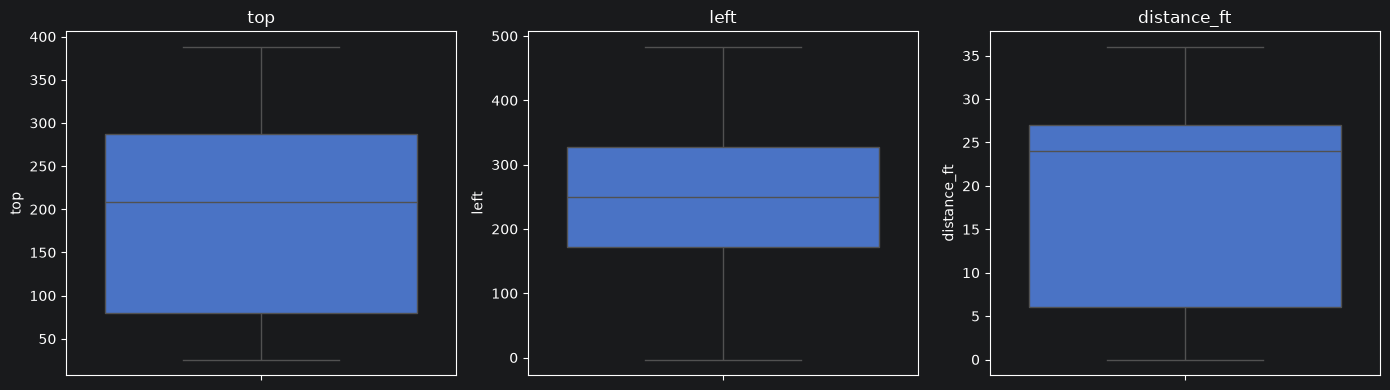

In [8]:
# Numerische Spalten auswählen (shot_type ist nur 2/3, daher nicht dabei)
numeric_cols = ["top", "left", "distance_ft"]

# Statistische Übersicht
print(df_duplicate[numeric_cols].describe())

# Boxplots für numerische Spalten erstellen
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df_duplicate[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [9]:
# Ausreißer mit IQR-Methode identifizieren
for col in numeric_cols:
    Q1 = df_duplicate[col].quantile(0.25)
    Q3 = df_duplicate[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_duplicate[(df_duplicate[col] < lower_bound) | (df_duplicate[col] > upper_bound)]
    print(f"{col}: Grenzen [{lower_bound:.1f}, {upper_bound:.1f}] -> {len(outliers)} Ausreißer")

# Randwerte aus der Projektidee genauer ansehen
print("\nWürfe mit left < 0:")
print(df_duplicate[df_duplicate["left"] < 0][["top", "left", "distance_ft", "shot_type", "result"]])

print("\nDie 10 weitesten Würfe:")
print(df_duplicate.nlargest(10, "distance_ft")[["distance_ft", "shot_type", "result", "top", "left"]])

top: Grenzen [-230.5, 597.5] -> 0 Ausreißer
left: Grenzen [-62.0, 562.0] -> 0 Ausreißer
distance_ft: Grenzen [-25.5, 58.5] -> 0 Ausreißer

Würfe mit left < 0:
     top  left  distance_ft  shot_type  result
177   64    -1           24          3    True
606   59    -3           24          3    True

Die 10 weitesten Würfe:
      distance_ft  shot_type  result  top  left
311            36          3   False  336   459
41             35          3    True  384   344
94             34          3   False  388   231
851            34          3    True  362   370
920            34          3    True  358    93
1019           34          3   False  384   263
1181           34          3   False  378   319
125            33          3   False  366   358
147            33          3   False  352   102
286            33          3   False  379   174


### Dokumentation zu Aufgabe 7

- Untersucht habe ich `top`, `left` und `distance_ft` mit `describe()`, Boxplots und der IQR-Methode. `shot_type` habe ich ausgelassen, da die Spalte nur die Werte 2 und 3 enthält.
- Ergebnis der IQR-Methode: In allen drei Spalten gibt es 0 Ausreißer.
- Die weitesten Würfe (bis 36 ft) sind alle Dreier und damit echte, extreme Werte. Ich behalte sie.
- Randwerte: Zwei Würfe haben negative Positionen (`left` = -1 und -3). Es sind Dreier mit 24 ft (beide Treffer), vermutlich Eckendreier an der Seitenlinie. Es handelt sich um minimales Koordinatenrauschen, kein echter Fehler.

### Aufgabe 8

In [13]:
# Entscheidung: Ausreißer behalten (IQR-Prüfung in Aufgabe 7 ergab 0 Ausreißer)
print("Zeilen & Spalten nach Aufgabe 8:", df_duplicate.shape)

Zeilen & Spalten nach Aufgabe 8: (1434, 9)


### Dokumentation zu Aufgabe 8

- **Strategie:** Ausreißer behalten (weder Entfernen noch Capping).
- **Begründung:** Die IQR-Prüfung in Aufgabe 7 ergab in `top`, `left` und `distance_ft` 0 Ausreißer. Weite Dreier bis 36 ft sowie die Randwerte (`left` = -1 und -3 bei 24-ft-Dreiern) sind valide Spielwerte. Ein Entfernen würde echte Information verlieren, gerade bei der Frage nach der Trefferquote bei großer Distanz.
- **Ergebnis:** Alle 1.434 Zeilen und 9 Spalten bleiben erhalten.

### Aufgabe 9

In [14]:
categorical_cols = df_duplicate.select_dtypes(include=["string", "category"]).columns

# 1) Leerzeichen und Schreibweisen prüfen
for col in categorical_cols:
    s = df_duplicate[col].astype(str)
    print(f"{col}: Leerzeichen = {(s != s.str.strip()).sum()}, "
          f"Schreibweisen-Duplikate = {s.str.strip().str.lower().nunique() != s.nunique()}")

# 2) Format von time_remaining prüfen (erwartet M:SS oder MM:SS)
valid = df_duplicate["time_remaining"].str.fullmatch(r"\d{1,2}:\d{2}")
print("Ungültiges Format:", (~valid).sum())

# 3) Plausibilität: in Sekunden umrechnen, max. pro Viertel prüfen
parts = df_duplicate["time_remaining"].str.split(":", expand=True).astype(int)
df_duplicate["time_remaining_sec"] = parts[0] * 60 + parts[1]
print(df_duplicate.groupby("qtr", observed=True)["time_remaining_sec"].max())

# 4) qtr in die richtige Reihenfolge bringen
df_duplicate["qtr"] = pd.Categorical(
    df_duplicate["qtr"],
    categories=["1st Qtr", "2nd Qtr", "3rd Qtr", "4th Qtr", "1st OT"],
    ordered=True,
)
print(df_duplicate["qtr"].value_counts().sort_index())

qtr: Leerzeichen = 0, Schreibweisen-Duplikate = False
time_remaining: Leerzeichen = 0, Schreibweisen-Duplikate = False
Ungültiges Format: 0
qtr
1st OT     235
1st Qtr    704
2nd Qtr    711
3rd Qtr    708
4th Qtr    710
Name: time_remaining_sec, dtype: int64
qtr
1st Qtr    330
2nd Qtr    329
3rd Qtr    385
4th Qtr    380
1st OT      10
Name: count, dtype: int64


### Dokumentation zu Aufgabe 9

- Kategoriale Spalten: `qtr` (5 Werte) und `time_remaining` (Zeitangabe als Text).
- Geprüft: Leerzeichen, Groß-/Kleinschreibung, Tippfehler und unerwartete Kategorien. Ergebnis: keine Inkonsistenzen, `qtr` enthält nur 1st–4th Qtr und 1st OT.
- `time_remaining` hat durchgehend das Format M:SS. Ich habe zusätzlich `time_remaining_sec` (Sekunden) erstellt, weil sich damit der Spielverlauf für die Analyse leichter auswerten lässt.
- `qtr` habe ich als geordnete Kategorie angelegt (1st → 1st OT).

### Aufgabe 10


In [15]:
print("Finale Dimensionen:", df_duplicate.shape)

print("\nFehlende Werte:", df_duplicate.isnull().sum().sum())

print("\nDuplikate:", df_duplicate.duplicated().sum())

print("\nDatentypen:")
print(df_duplicate.dtypes)

print("\nErste Zeilen des bereinigten Datensatzes:")
print(df_duplicate.head())

Finale Dimensionen: (1434, 10)

Fehlende Werte: 0

Duplikate: 0

Datentypen:
top                            int64
left                           int64
date                  datetime64[us]
qtr                         category
time_remaining                   str
result                          bool
shot_type                      int64
distance_ft                    int64
lead                            bool
time_remaining_sec             int64
dtype: object

Erste Zeilen des bereinigten Datensatzes:
   top  left       date      qtr time_remaining  result  shot_type  \
0   63   300 2022-10-18  1st Qtr           7:27   False          2   
1  133   389 2022-10-18  1st Qtr           7:22    True          2   
2  326   247 2022-10-18  1st Qtr           7:11   False          3   
3  249    89 2022-10-18  1st Qtr           5:16   False          3   
4  282   158 2022-10-18  1st Qtr           3:52   False          3   

   distance_ft  lead  time_remaining_sec  
0            6  True            

### Dokumentation zu Aufgabe 10

- Finale Dimension: 1434 Zeilen und 10 Spalten
- Keine fehlenden Werte, keine Duplikate
- Datentypen: `date` als datetime, `qtr` als geordnete category, `time_remaining_sec` als int, `result` und `lead` als bool
- Ausreißer: keine entfernt, da alle Werte valide sind
- Inkonsistenzen: keine gefunden
- Der Datensatz ist bereit für die Analyse

### Aufgabe 11

In [16]:
df_duplicate.to_csv("stephen_curry_cleaned.csv", index=False)
print("Bereinigter Datensatz wurde gespeichert!")

Bereinigter Datensatz wurde gespeichert!


### Reflexion:

1. **Hauptprobleme:**
   - Der Datensatz war schon sehr sauber: keine fehlenden Werte, keine Duplikate, keine Ausreißer
   - `team` und `season` enthielten nur einen Wert, `color` hätte das Ergebnis verraten
   - `lebron_team_score` war irreführend benannt (enthält die Punkte von GSW)
   - `date` war als Text gespeichert

2. **Wichtigste Schritte:**
   - Entfernen der Spalten, die nichts bringen oder `result` verraten (Data Leakage)
   - Konvertieren von `date` und `qtr`
   - Plausibilitätsprüfung von `time_remaining` und Umrechnung in Sekunden

3. **Entfernte Daten:**
   - 0 Zeilen
   - 6 Spalten (`team`, `season`, `color`, `lebron_team_score`, `opponent`, `opponent_team_score`)
   - Neu hinzugekommen ist `time_remaining_sec`, dadurch 10 Spalten

4. **Herausforderungen:**
   - Ich musste entscheiden, ob ich Ausreißer entferne. Weite Dreier und Randwerte sind echte Würfe, deshalb habe ich alles behalten
   - Ich habe mich bei der Season verlesen (22/23 statt 23/24)

5. **Bereitschaft für Analyse:**
   - Ja. Einschränkung: Es gibt keine Infos zum Verteidigungsdruck, und es ist nur ein Spieler in einer Saison